# Interface of energy transition model with hydrogen 

The hydrogen demand is served by SMR (grey), SMR + CCS (blue) and the grid electrolyser (green). Hydrogen storage, the pure green route and pink hydrogen are in the package with additions, which runs the same analysis with them in every run.

- **Hydrogen is a demand.** The demand table has one new demand, `industrial_h2`: 1.3 Mt/yr for refineries and ammonia (Elzenga et al., 2025). It is the same in every period and scenario, and flat over the hours.

- **End-use technologies feed that demand directly:** SMR (grey hydrogen), SMR + CCS (blue) and the electrolyser (green, grid electricity).
  The reformers that exist in 2020 are the 2020 stock (`SMR - existing`).
  
- **The scenarios differ only in water availability.** Water itself is not modelled. The scenario limits how much electrolyser capacity can be built, in the capacity constraints of the technology table. **The base is the scenario without water scarcity.**

## 0. Imports and settings

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
import logging
logging.getLogger('pypsa').setLevel(logging.ERROR)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa
from IPython.display import Image, display

from energy_model import h2_presets as h2
from energy_model.h2_scenario import electrolyser_reference


try:
    from figures.plots.h2_results import (summary, compare, policy_table, h2_balance,
                                           limit_cost, cumulative_co2, subsidy_cost,
                                           gas_use, electricity_mix, co2_stored_by_sector)
except ImportError:
    summary = compare = policy_table = h2_balance = None
    limit_cost = cumulative_co2 = subsidy_cost = None
    gas_use = electricity_mix = co2_stored_by_sector = None


try:
    from figures.plots import h2_plots as hp
    from figures.plots.h2_sankey import plot_sankeys, plot_sankeys_row
    from figures.plots import system_plots as sp
    from figures.plots import presentation as pres
except ImportError:
    # The published model intentionally contains only the core interface modules.
    hp = None
    sp = None
    pres = None
    plot_sankeys = plot_sankeys_row = None
ADDITIONS, SET_LONG = False, 'Published FinalModel_H2'
import run_batch                      # list of runs (RUNS) and a cached run() function

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_columns', 40)

SOLVER = 'gurobi'
FIG = 'results/plots'
RERUN = False          # True = re-solve even if results/runs/<name>.nc already exists
os.makedirs(FIG, exist_ok=True)
SHORT = h2.SHORT_NAMES          # {'S1': 'Base', 'S2': 'Medium', 'S3': 'Scarce'}
print('Package', SET_LONG)

def load(name):
    n = pypsa.Network(run_batch.run(name, solver=SOLVER, rerun=RERUN))
    n.name = name
    return n

def save(fig, name):
    fig = getattr(fig, 'figure', fig)
    for ext in ('png', 'svg'):
        fig.savefig(f'{FIG}/{name}.{ext}', dpi=300, bbox_inches='tight', facecolor='white')

Package Published FinalModel_H2


## 1. Importing the course parameters and plots

In [2]:
# Default parameters 

db_dir = 'input_databases//h2_nl'     # hydrogen database (real numbers); 'input_databases//default' = course model
years = [2020, 2030, 2040, 2050]      # model years
t_res = 15                            # intra-year temporal resolution (hours)
rt = 0.07                             # technical discount rate (annuities)
rs = 0.01                             # social discount rate (weights of the years in the objective)
passenger_cars_cf = 40 * 0.1          # passenger cars conversion factor (km/h)

In [3]:
# Handy plotting functions
try:
    from figures.plots.system_plots import course_plot_main_ebs as plot_main_ebs, course_plot_elc_emi as plot_elc_emi
    from figures.plots.system_plots import course_plot_h2_eb as plot_h2_eb
except ImportError:
    plot_main_ebs = plot_elc_emi = plot_h2_eb = None

# 2. Choosing the scenario 

In [4]:
SCENARIO = 'S1'                       # 'S1' Base, 'S2' Medium, 'S3' Scarce

**The selected scenario**  loads the saved run of `SCENARIO` and draws the course plots. If the run is not on disk, it is solved, together with Base without additions if it needs its electrolyser capacity. The last plot is the balance of the hydrogen demand bus: the technologies on one side, the demand on the other.

In [5]:
n = load(SCENARIO)
print(SCENARIO, SHORT[SCENARIO], '| objective:', f'{n.objective:.4e}')
if plot_main_ebs is not None:
    plot_main_ebs(n)
    plot_elc_emi(n)
    plot_h2_eb(n)
else:
    print('Core model loaded; optional course plotting modules are not included in this package.')

S1: already on disk
S1 Base | objective: 1.0580e+12
Core model loaded; optional course plotting modules are not included in this package.


## 3. The hydrogen database

`build_h2_database.py` starts from the final course database (`input_databases/default`) and writes **one** hydrogen database, `h2_nl`. It contains:
- the final model's database, with its 2020 calibration unchanged;
- the hydrogen demand and the three technologies;
- the electrolyser on desalinated seawater (a green lever, off unless a run switches it on);
- the selected Dutch input values and their cited sources.

This package has no additions: the database has no hydrogen storage and no dedicated plants.

In [6]:
import build_h2_database
REBUILD = False                 # True = rebuild input_databases/h2_nl (after editing build_h2_database.py)
if REBUILD or not os.path.exists('input_databases/h2_nl/technologies.xlsx'):
    build_h2_database.main()
s = pd.read_excel('input_databases/h2_nl/technologies.xlsx', sheet_name='static_parameters')
s['Technology'] = s['Technology'].ffill()
techs = ['SMR', 'SMR - existing', 'SMR CCS', 'Electrolyser', 'Electrolyser - seawater', 'H2 storage',
         'Solar PV - dedicated', 'Wind turbine - offshore - dedicated', 'Electrolyser - dedicated',
         'Nuclear plant - dedicated', 'Electrolyser - nuclear']
techs = [t for t in techs if t in set(s.Technology)]
s[s.Technology.isin(techs)].pivot_table(index='Technology', columns='Parameter', values='Value', aggfunc='first').reindex(
    columns=['Sector', 'Type', 'bus0', 'bus1', 'bus2', 'bus3', 'Start year']).loc[techs]

Parameter,Sector,Type,bus0,bus1,bus2,bus3,Start year
Technology,,,,,,,
SMR,Industry,Link,Gas supply,Hydrogen,CO2 atmosphere,NaN,NaN
SMR - existing,Industry,Link,Gas supply,Hydrogen,CO2 atmosphere,NaN,NaN
SMR CCS,Industry,Link,Gas supply,Hydrogen,CO2 atmosphere,CO2 storage,2030
Electrolyser,Industry,Link,Electricity,Hydrogen,NaN,NaN,2030
Electrolyser - seawater,Industry,Link,Electricity,Hydrogen,NaN,NaN,2030
H2 storage,Industry,Store,Hydrogen,NaN,NaN,NaN,2030


In [7]:
d = pd.read_excel('input_databases/h2_nl/technologies.xlsx', sheet_name='dynamic_parameters')
d['Technology'] = d['Technology'].ffill()
d[d.Technology.isin(['SMR', 'SMR CCS', 'Electrolyser', 'H2 storage'])].set_index(['Technology', 'Parameter'])[
    ['Unit', 2020, 2030, 2040, 2050]]

Unit     2020     2030     2040     2050
Technology   Parameter                                                    
Electrolyser CAPEX                €/kW 3,666.70 2,661.30 1,923.10 1,428.60
             FOM                  €/kW   110.00    79.80    57.70    42.90
             VOM                 €/kWh     0.00     0.00     0.00     0.00
             Efficiency            NaN     0.60     0.62     0.65     0.70
             Lifetime            years    25.00    25.00    25.00    25.00
SMR          CAPEX                €/kW   867.30   867.30   867.30   867.30
             FOM                  €/kW    43.40    43.40    43.40    43.40
             VOM                 €/kWh     0.00     0.00     0.00     0.00
             Efficiency            NaN     0.76     0.76     0.76     0.76
             Lifetime            years    30.00    30.00    30.00    30.00
             Emissions     tCO2/MWh_th     0.20     0.20     0.20     0.20
SMR CCS      CAPEX                €/kW 1,330.00 1,330.00 1,330.00 1,330.00
             FOM                  €/kW    66.50    66.50    66.50    66.50
             VOM                 €/kWh     0.00     0.00     0.00     0.00
             Efficiency            NaN     0.69     0.69     0.69     0.69
             Lifetime            years    30.00    30.00    30.00    30.00
             Emissions     tCO2/MWh_th     0.02     0.02     0.02     0.02
             Captured CO2  tCO2/MWh_th     0.18     0.18     0.18     0.18
H2 storage   CAPEX               €/kWh     0.90     0.90     0.85     0.80
             FOM                 €/kWh     0.02     0.02     0.02     0.02
             VOM                 €/kWh     0.00     0.00     0.00     0.00
             Efficiency            NaN     1.00     1.00     1.00     1.00
             Lifetime            years    45.00    45.00    45.00    45.00

In [8]:
dem = pd.read_excel('input_databases/h2_nl/demand.xlsx', sheet_name='demands')
display(dem[dem.Demand == 'industrial_h2'][['Demand', 'Bus', 'Unit', 'Start_value', 'Exponent']])
par = pd.read_excel('input_databases/h2_nl/supply.xlsx', sheet_name='resources_parameters')
par[par.Parameter == 'Price'].set_index(['Resource', 'Unit'])[[2020, 2030, 2040, 2050]]

,Demand,Bus,Unit,Start_value,Exponent
5,industrial_h2,Hydrogen,MWh,"43,329,000.00",0.00


,,2020,2030,2040,2050
Resource,Unit,,,,
Gas supply,€/MWh_th,13.30,26.60,28.90,27.80
Gasoline supply,€/MWh_th,200.00,NaN,NaN,500.00
Biomass supply,€/MWh_th,40.00,NaN,NaN,NaN
Nuclear supply,€/MWh_th,1.60,NaN,NaN,NaN
CO2 atmosphere,€/tCO2,30.30,110.00,180.00,250.00
CO2 storage,€/tCO2,55.00,55.00,45.00,40.00


## 4. The three scenarios

**Base without additions sets the water.** Its electrolyser capacity per vintage sets the limit of Medium (50%); Scarce has no electrolysers. The limits go into the capacity constraints of the technology table, the course's own way of limiting how much of a technology can be built.

**In every run the limits stay the same in MW.** The water that is available does not change when costs change or technologies are added. With more than one electrolyser technology, one joint constraint keeps them together under the limit.

In [9]:
runs = {SHORT[s]: load(s) for s in ['S1', 'S2', 'S3']}
water_ref = electrolyser_reference(load(run_batch.BASE_NOADD))
print('Electrolyser capacity of Base without additions per vintage (MW of hydrogen output):', json.dumps(water_ref))
print('Limit of Medium per vintage (MW of hydrogen output, all electrolysers together):',
      json.dumps(runs['Medium'].meta['scenario'].get('_electrolyser_cap_total_mw_h2')
                 or runs['Medium'].meta['scenario']['_electrolyser_caps_mw_h2']))

S1: already on disk
S1: already on disk
S2: already on disk
S3: already on disk
S1: already on disk
Electrolyser capacity of Base without additions per vintage (MW of hydrogen output): {"Electrolyser": {"2030": 0.0, "2040": 0.0, "2050": 7938.656292899535}}
Limit of Medium per vintage (MW of hydrogen output, all electrolysers together): {"2030": 0.0, "2040": 0.0, "2050": 3969.3281464497677}


In [10]:
if compare is not None:
    cols = ['Green (grid electrolysis)', 'Pure green (dedicated wind + solar)', 'Pink (nuclear electrolysis)',
            'Blue (SMR + CCS)', 'Grey (SMR)', 'Electrolysis share (%)', 'Electrolyser capacity (GW_el)',
            'Electrolyser full-load hours (h/yr)', 'H2 storage (GWh)', 'Gas use, total (TWh/yr)', 'Gas for H2 (TWh/yr)',
            'CO2 total (Mt/yr)', 'CO2 captured from H2 (Mt/yr)', 'Water for H2 (Mm3/yr)', 'System cost (bn €/yr)']
    pd.concat({p: compare(runs, period=p)[cols] for p in [2030, 2040, 2050]})
else:
    print('figures.plots.h2_results not available — skipping comparison table')

figures.plots.h2_results not available — skipping comparison table


In [11]:
import os
print(os.path.exists('figures/plots/h2_results.py'))
print(os.listdir('figures/plots') if os.path.exists('figures/plots') else 'figures/plots not found')

True
['ensemble.py', 'ensemble_analysis.py', 'h2_plots.py', 'h2_results.py', 'h2_sankey.py', 'presentation.py', 'results_summary.py', 'system_plots.py', '__init__.py', '__pycache__']


In [36]:
from figures.plots.h2_results import compare


ImportError: cannot import name 'ELECTROLYSIS' from 'energy_model.model' (/mnt/c/users/mara/documents/uva_csp/modeling_transitions/group/code_group/mt_group/FinalModel_H2/energy_model/model.py)

In [37]:
print(os.path.exists('figures/__init__.py'))
print(os.path.exists('figures/plots/__init__.py'))

False
False


In [38]:
open('figures/__init__.py', 'w').close()
open('figures/plots/__init__.py', 'w').close()

In [12]:
cols = ['Green (grid electrolysis)', 'Pure green (dedicated wind + solar)', 'Pink (nuclear electrolysis)',
        'Blue (SMR + CCS)', 'Grey (SMR)', 'Electrolysis share (%)', 'Electrolyser capacity (GW_el)',
        'Electrolyser full-load hours (h/yr)', 'H2 storage (GWh)', 'Gas use, total (TWh/yr)', 'Gas for H2 (TWh/yr)',
        'CO2 total (Mt/yr)', 'CO2 captured from H2 (Mt/yr)', 'Water for H2 (Mm3/yr)', 'System cost (bn €/yr)']
pd.concat({p: compare(runs, period=p)[cols] for p in [2030, 2040, 2050]})

TypeError: 'NoneType' object is not callable

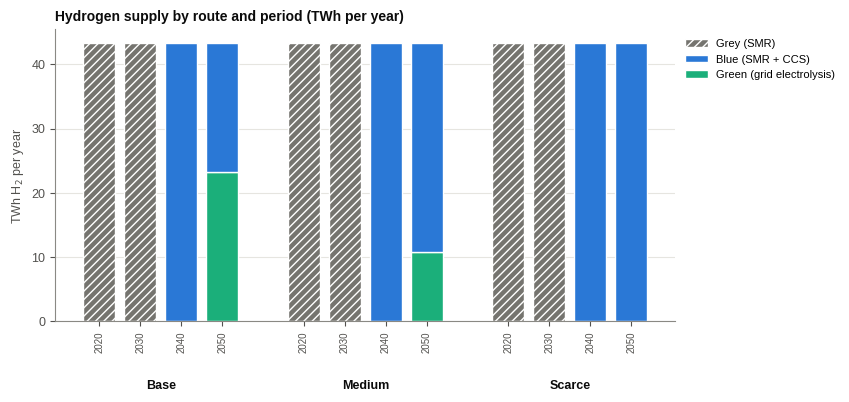

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
hp.plot_h2_routes(runs, ax=ax, title='Hydrogen supply by route and period (TWh per year)')
save(ax, 'T1_1_h2_routes')

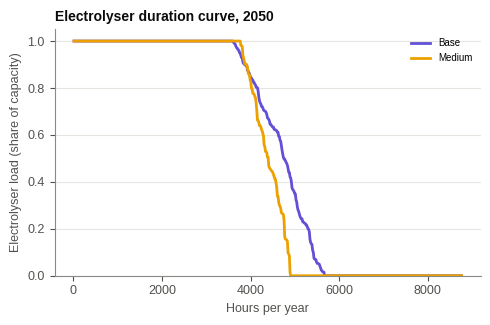

In [12]:
ax = hp.plot_electrolyser_duration(runs, 2050)
save(ax, 'T1_1_electrolyser_duration_2050')

**Scarce at 0% or 10%?** The pessimistic case "can be zero, it can be ten percent". The report uses 0%, because electrolysis gets no water in a drought. `S3_10pct` allows 10% of the capacity of Base without additions.

In [13]:
sc = {'Scarce (0%)': runs['Scarce'], 'Scarce (10%)': load('S3_10pct'), 'Medium (50%)': runs['Medium']}
policy_table(sc, ref='Scarce (0%)')

S3_10pct: already on disk


,Scarce (0%),Scarce (10%),Medium (50%)
"System cost 2020-2059, discounted (bn €)","1,064.44","1,063.87","1,061.74"
Green share 2050 (%),0.00,4.65,25.02
H2 2050 (TWh/yr): green / pure green / pink / blue / grey,0.0 / 0.0 / 0.0 / 43.3 / 0.0,2.0 / 0.0 / 0.0 / 41.3 / 0.0,10.8 / 0.0 / 0.0 / 32.5 / 0.0
Electrolyser capacity 2050 (GW_el),0.00,0.71,3.53
Electrolyser full-load hours 2050 (h/yr),0.00,"4,071.84","4,383.20"
"Electrolyser investment 2020-2059 (bn €, overnight)",0.00,0.71,3.53
Gas use 2020-2059 (TWh),"11,500.32","11,444.95","11,265.50"
Gas use 2050 (TWh/yr),189.90,185.61,168.90
Gas for H2 2050 (TWh/yr),62.80,59.88,47.09
Electricity generation 2050 (TWh/yr),135.24,139.71,157.54


**How to read this.**
- **2030:** the existing reformers (grey) make all the hydrogen in every scenario.
- **2040:** blue hydrogen, because it is still cheaper than green.
- **2050:** green hydrogen is cheapest whenever electricity is cheap.
  - Without hydrogen storage and with a flat demand, the electrolysers can never usefully be larger than the demand itself. Base builds exactly that, and blue hydrogen fills the hours with expensive electricity.
  - Medium can build half of that capacity, and Scarce none.

## 5. The policy story

Compare the scenarios on what they mean for policymakers:
- the cost of the system;
- the gas that has to be imported;
- the electricity generation mix;
- the money saved by building a smaller electrolyser.

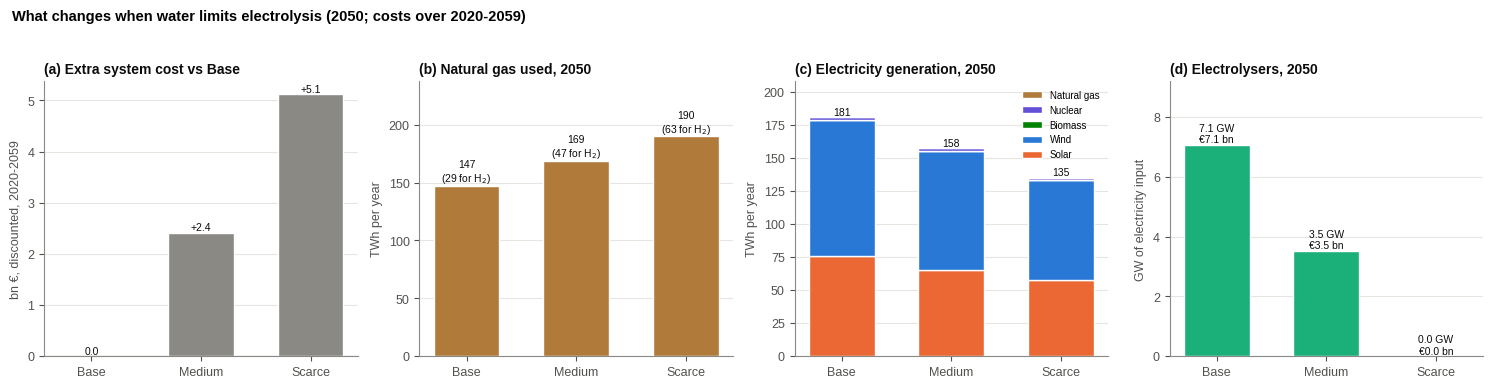

In [14]:
fig = hp.plot_policy_story(runs, ref='Base')
save(fig, 'P_policy_story_2050')

In [15]:
display(pres.scarcity_numbers(runs))
policy_table(runs, ref='Base')

,Medium,Scarce
Extra system cost (bn €),2.41,5.12
Extra CO2 (Mt),48.52,94.21
Extra gas imports (TWh),218.27,453.09
Cost per kg of green H2 lost (€/kg),0.92,1.04


,Base,Medium,Scarce
"System cost 2020-2059, discounted (bn €)","1,059.32","1,061.74","1,064.44"
Green share 2050 (%),53.56,25.02,0.00
H2 2050 (TWh/yr): green / pure green / pink / blue / grey,23.2 / 0.0 / 0.0 / 20.1 / 0.0,10.8 / 0.0 / 0.0 / 32.5 / 0.0,0.0 / 0.0 / 0.0 / 43.3 / 0.0
Electrolyser capacity 2050 (GW_el),7.07,3.53,0.00
Electrolyser full-load hours 2050 (h/yr),"4,691.62","4,383.20",0.00
"Electrolyser investment 2020-2059 (bn €, overnight)",7.07,3.53,0.00
Gas use 2020-2059 (TWh),"11,047.23","11,265.50","11,500.32"
Gas use 2050 (TWh/yr),147.24,168.90,189.90
Gas for H2 2050 (TWh/yr),29.16,47.09,62.80
Electricity generation 2050 (TWh/yr),180.90,157.54,135.24


**The over-dimensioned plant.** The sensitivity represents a plant built for abundant water before a drought: build the electrolysers for abundant water, and then a drought comes.
- In `S2_oversized` the plant is as big as in Base. Water lets it run at no more than 50% of its capacity in any hour, the same water as Medium.
- The difference with Medium is the cost of having built for the optimistic case.

In [16]:
over = {'Medium (plant sized for the drought)': runs['Medium'], 'Medium, Base plant (oversized)': load('S2_oversized')}
policy_table(over, ref='Medium (plant sized for the drought)')

S2_oversized: already on disk


,Medium (plant sized for the drought),"Medium, Base plant (oversized)"
"System cost 2020-2059, discounted (bn €)","1,061.74","1,064.64"
Green share 2050 (%),25.02,25.02
H2 2050 (TWh/yr): green / pure green / pink / blue / grey,10.8 / 0.0 / 0.0 / 32.5 / 0.0,10.8 / 0.0 / 0.0 / 32.5 / 0.0
Electrolyser capacity 2050 (GW_el),3.53,7.07
Electrolyser full-load hours 2050 (h/yr),"4,383.20","2,191.60"
"Electrolyser investment 2020-2059 (bn €, overnight)",3.53,7.07
Gas use 2020-2059 (TWh),"11,265.50","11,265.50"
Gas use 2050 (TWh/yr),168.90,168.90
Gas for H2 2050 (TWh/yr),47.09,47.09
Electricity generation 2050 (TWh/yr),157.54,157.54


## 6. Sankey diagrams and the whole energy system

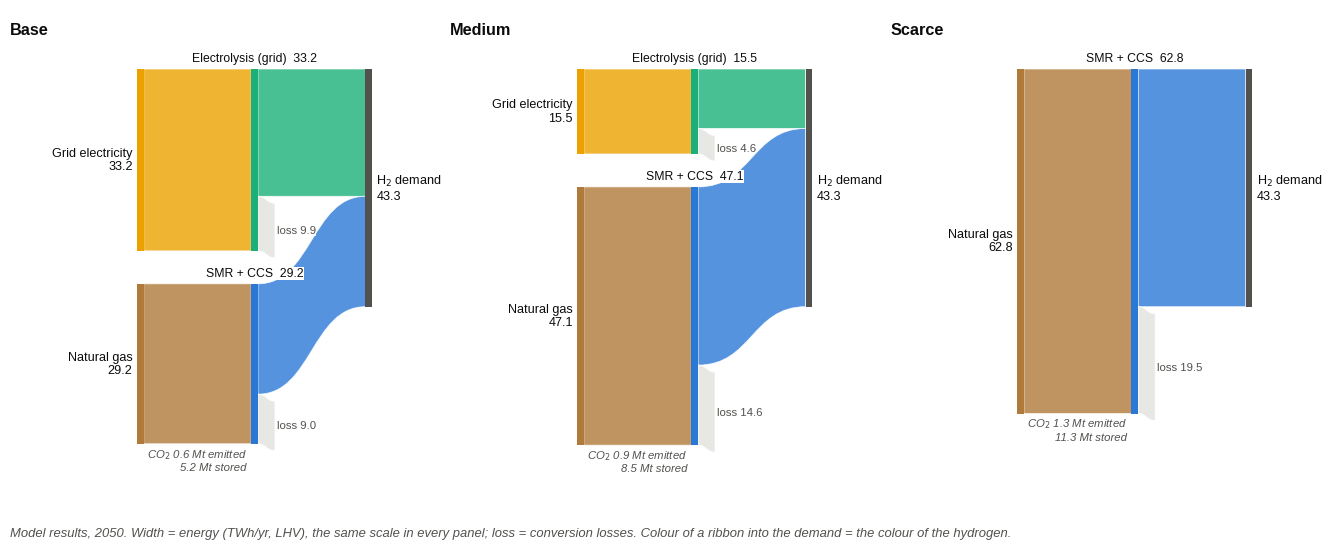

In [17]:
fig = plot_sankeys_row(runs, period=2050)
save(fig, 'T1_1_sankey_2050')

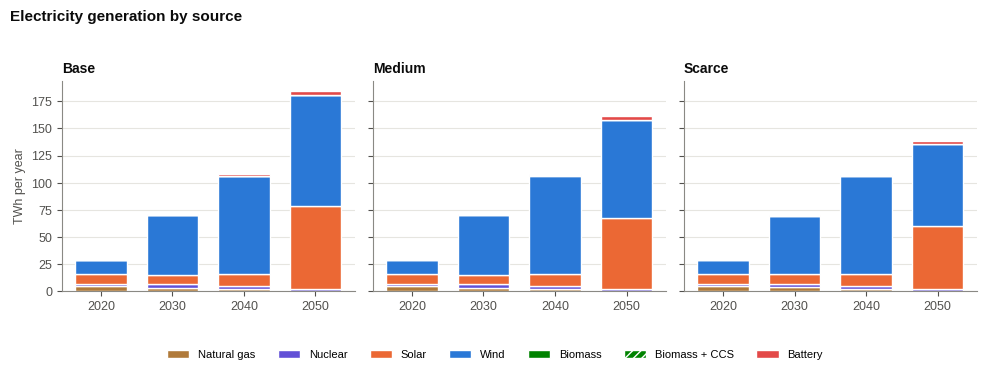

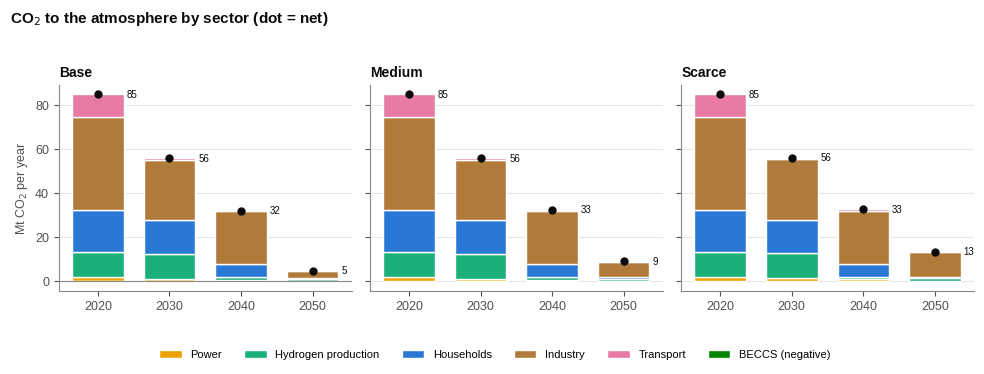

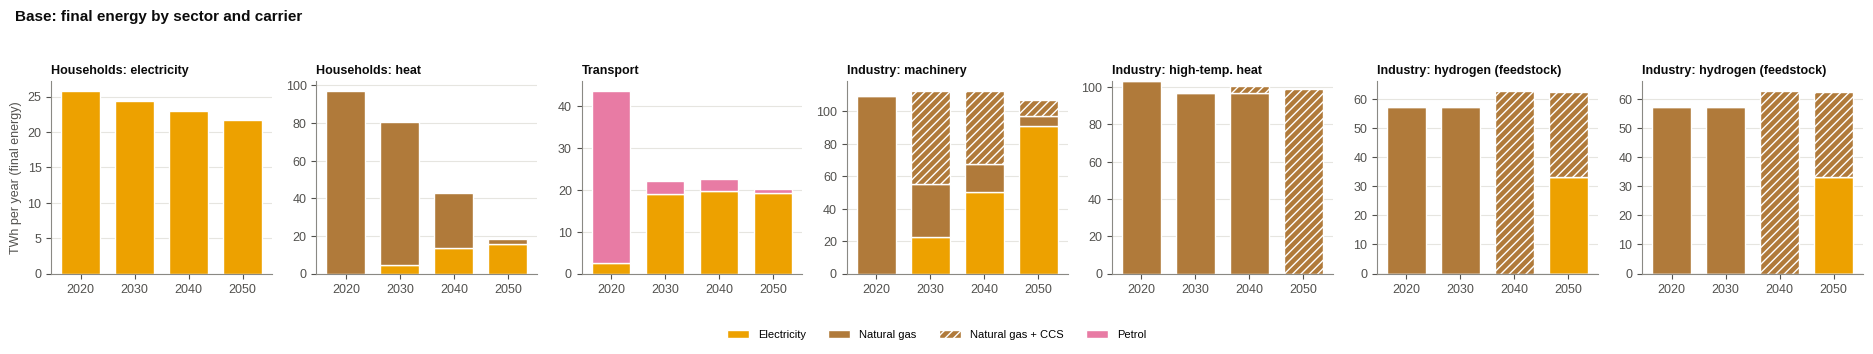

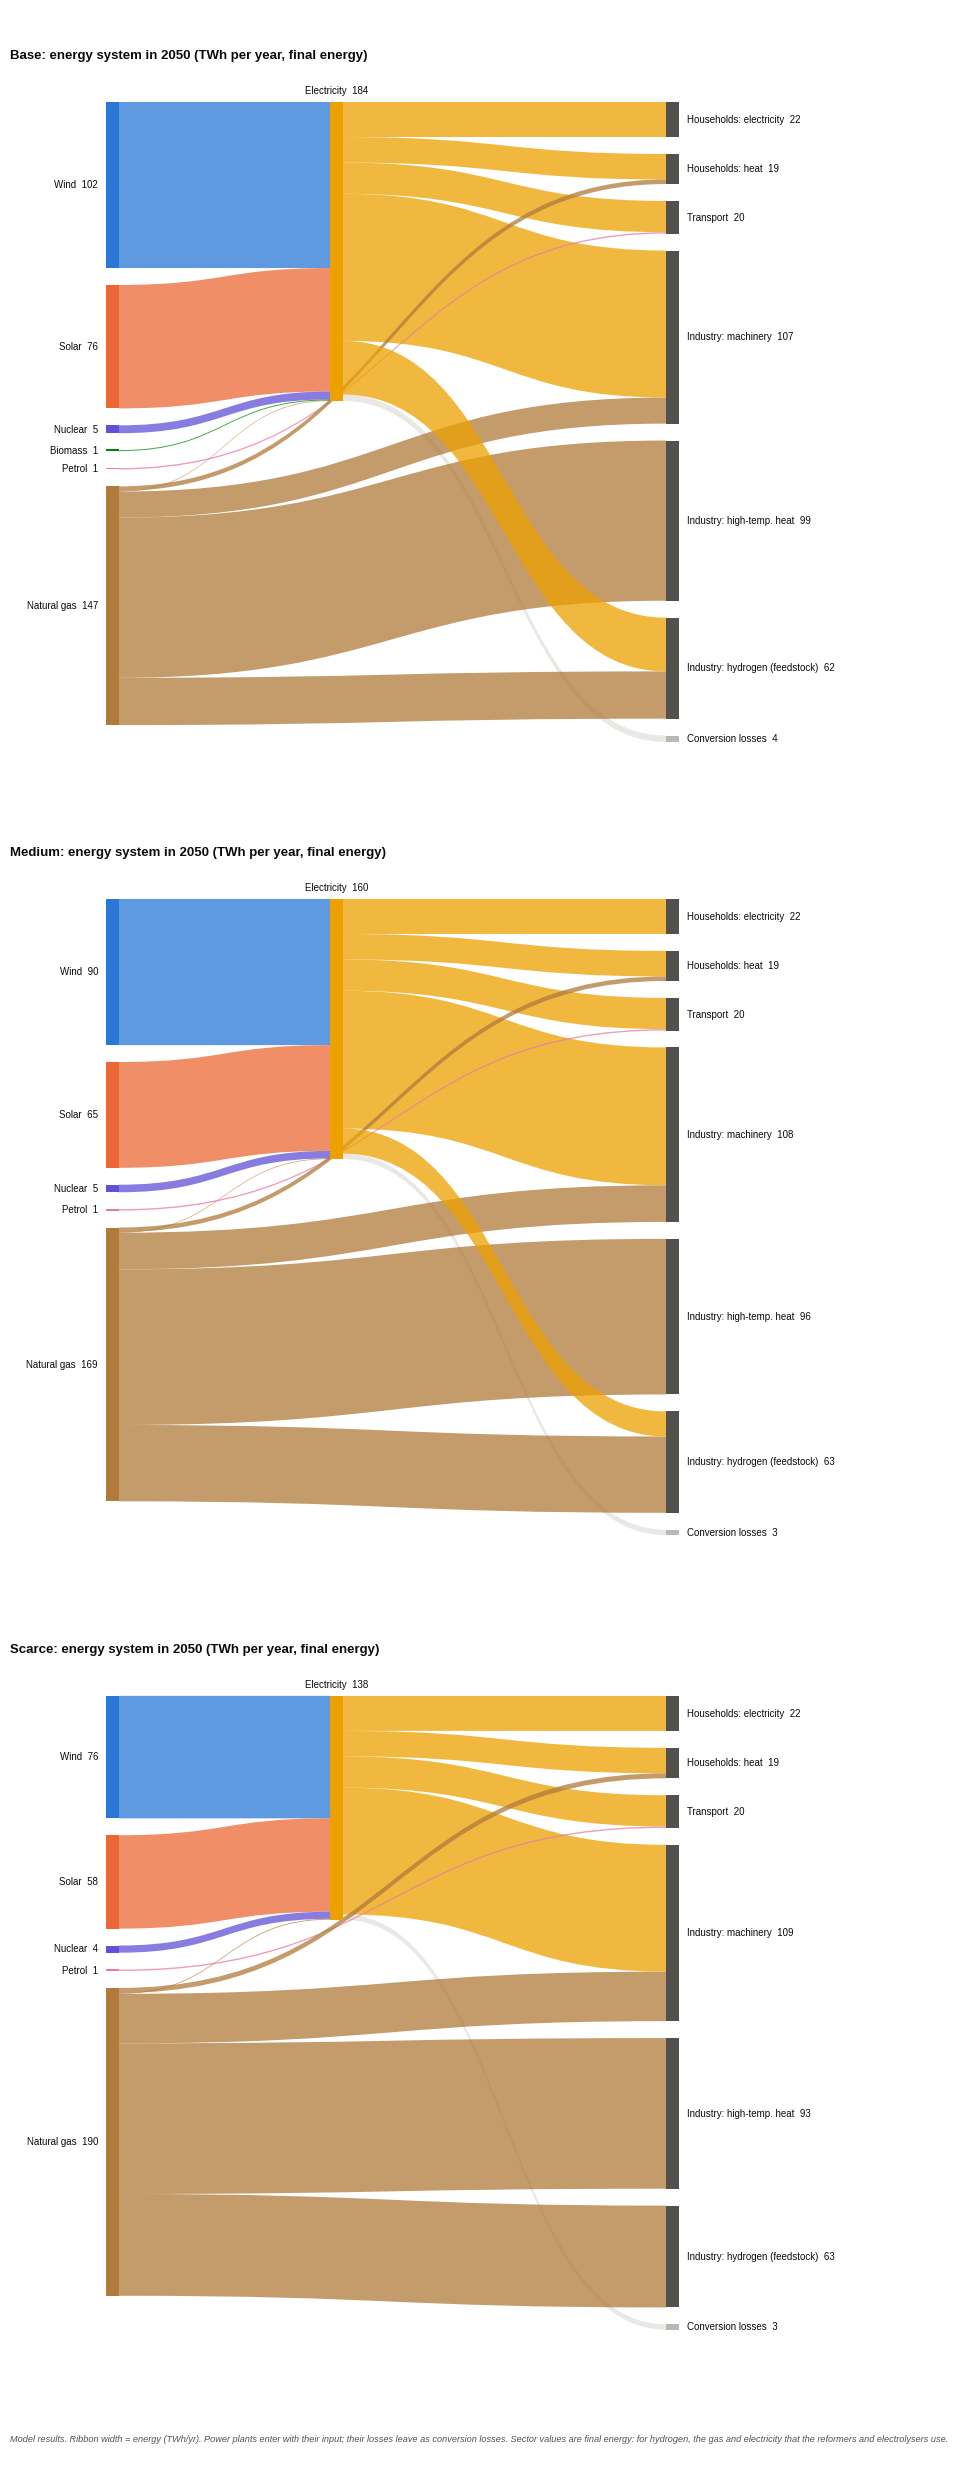

In [18]:
save(sp.plot_electricity_supply(runs), 'S_electricity_supply')
save(sp.plot_co2_by_sector(runs), 'S_co2_by_sector')
save(sp.plot_energy_balance(runs['Base'], 'Base: final energy by sector and carrier'), 'S_energy_balance_Base')
save(sp.plot_system_sankey(runs, 2050), 'S_system_sankey_2050')

**CO₂ storage is capped** (10 / 22 / 25 Mt/yr in 2030 / 2040 / 2050). Blue hydrogen and the industrial CCS compete for it, so less electrolysis means more CO₂ from industry.

In [19]:
pd.concat({k: co2_stored_by_sector(n) for k, n in runs.items()}, axis=1).round(1)

Base                                              \
       Hydrogen (blue) Industry Power (gas) Power (biomass, BECCS)   
period                                                               
2020              0.00     0.00        0.00                   0.00   
2030              0.00    10.00        0.00                   0.00   
2040             11.30     8.50        0.00                   0.40   
2050              5.20    19.50        0.00                   0.20   

                Medium                                              \
       Hydrogen (blue) Industry Power (gas) Power (biomass, BECCS)   
period                                                               
2020              0.00     0.00        0.00                   0.00   
2030              0.00    10.00        0.00                   0.00   
2040             11.30     8.40        0.00                   0.00   
2050              8.50    16.50        0.00                   0.00   

                Scarce                                              
       Hydrogen (blue) Industry Power (gas) Power (biomass, BECCS)  
period                                                              
2020              0.00     0.00        0.00                   0.00  
2030              0.00    10.00        0.00                   0.00  
2040             11.30     8.50        0.00                   0.00  
2050             11.30    13.70        0.00                   0.00

## 7. Variations within the scenarios

**(2a) Cheaper electrolysers:** a subsidy of 20% or 40% of the investment. The limit of Medium stays the same in MW.

In [20]:
display(pres.subsidy_table())

,scenario,variant,Electrolysers (GW_el),Electrolysis share (%),"Subsidy (bn €, overnight)",Extra system cost (bn €),CO2 avoided (Mt)
0,Base,central,7.07,53.56,0.00,0.00,0.00
1,Base,subsidy 20%,7.07,53.56,1.41,0.00,-0.00
2,Base,subsidy 40%,7.07,53.56,2.83,0.00,0.00
3,Base,low electrolyser CAPEX,7.07,53.56,0.00,-2.90,-0.00
4,Medium,central,3.53,25.02,0.00,0.00,0.00
5,Medium,subsidy 20%,3.53,25.02,0.71,-0.00,-0.00
6,Medium,subsidy 40%,3.53,25.02,1.41,0.00,-0.00
7,Medium,low electrolyser CAPEX,3.53,25.02,0.00,-1.45,0.00


**(2b) The CO₂ price:** low (170 €/t in 2050), central (250) and high (500), in each scenario.

In [21]:
co2 = {f'{SHORT[s]}, {p}': (load(f'{s}_co2{p}') if p != 'central' else runs[SHORT[s]])
       for s in ['S1', 'S2', 'S3'] for p in ['low', 'central', 'high']}
compare(co2, period=2050)[['Green (grid electrolysis)', 'Blue (SMR + CCS)', 'Grey (SMR)', 'Electrolysis share (%)',
                           'Electrolyser capacity (GW_el)', 'CO2 total (Mt/yr)', 'System cost (bn €/yr)']]

S1_co2low: already on disk


S1_co2high: already on disk


S2_co2low: already on disk


S2_co2high: already on disk


S3_co2low: already on disk


S3_co2high: already on disk


,Green (grid electrolysis),Blue (SMR + CCS),Grey (SMR),Electrolysis share (%),Electrolyser capacity (GW_el),CO2 total (Mt/yr),System cost (bn €/yr)
run,,,,,,,
"Base, low",13.27,30.06,0.00,30.62,5.05,9.40,30.46
"Base, central",23.21,20.12,0.00,53.56,7.07,4.66,31.46
"Base, high",31.67,11.65,0.00,73.10,7.07,-3.00,32.05
"Medium, low",8.83,34.50,0.00,20.39,3.53,11.06,30.46
"Medium, central",10.84,32.49,0.00,25.02,3.53,9.00,31.79
"Medium, high",14.86,28.46,0.00,34.31,3.53,2.59,33.62
"Scarce, low",0.00,43.33,0.00,0.00,0.00,14.91,30.50
"Scarce, central",0.00,43.33,0.00,0.00,0.00,13.19,32.20
"Scarce, high",0.00,43.33,0.00,0.00,0.00,8.46,35.24


**(3a–c) Batteries where electrolysis is limited (Medium):** half the cost (3a), and 8 hours instead of 4 (3c). The time series (3b) shows how the electrolysers and batteries run.

S2_battery_cheap: already on disk


S2_battery_8h: already on disk


,Battery (GW),Curtailment (TWh/yr),Electrolyser full-load hours (h/yr),Electrolysis share (%),System cost (bn €/yr)
run,,,,,
Medium,6.48,20.69,"4,383.20",25.02,31.79
"Medium, half-price batteries",30.07,17.38,"4,637.71",26.47,31.38
"Medium, 8 h batteries",3.24,20.69,"4,383.20",25.02,31.79


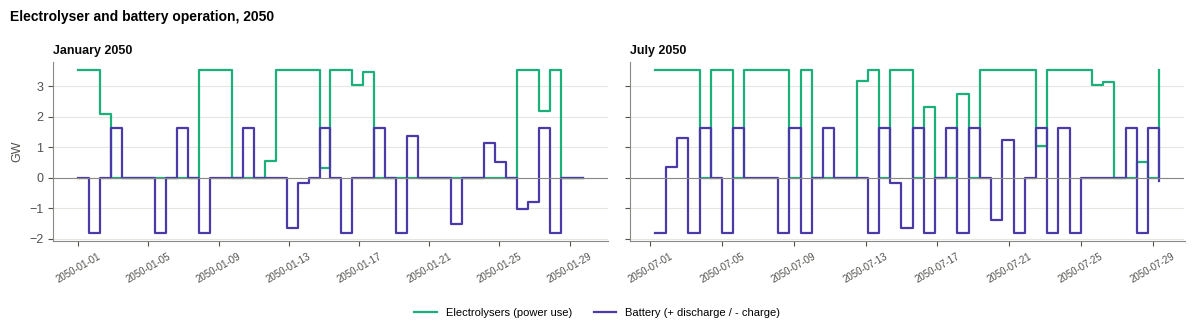

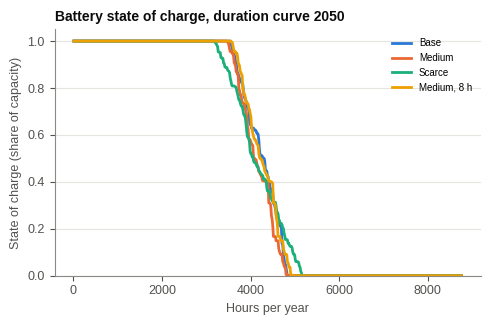

In [22]:
bat = {'Medium': runs['Medium'], 'Medium, half-price batteries': load('S2_battery_cheap'),
       'Medium, 8 h batteries': load('S2_battery_8h')}
display(compare(bat, period=2050)[['Battery (GW)', 'Curtailment (TWh/yr)', 'Electrolyser full-load hours (h/yr)',
                                   'Electrolysis share (%)', 'System cost (bn €/yr)']])
fig = hp.plot_operation_timeseries(runs['Medium'], 2050)
save(fig, 'T1_3b_operation_Medium')
ax = hp.plot_soc_duration({**runs, 'Medium, 8 h': bat['Medium, 8 h batteries']}, 2050)
save(ax, 'T1_3c_soc_duration')

## 8. Green levers within the water scenarios

How could green policy, technology or subsidies get more green hydrogen when water is scarce? Three levers, each compared with the same scenario without it:
- **Desalinated water** (`desal=True`): an electrolyser on desalinated seawater, **outside** the water limit, at €0.03 per kg extra. `S3_desal_x10` tries €0.30/kg.
- **Production subsidy** (`h2_production_subsidy` = €1 or €2 per kg of electrolytic hydrogen): a negative variable cost of every electrolyser. It is a transfer, so `economic_cost()` adds it back.
- **Mandate** (`green_mandate={2040: 0.6, 2050: 0.6}`): at least 60% of the hydrogen from electrolysis (RED III: 60% renewable hydrogen in industry by 2035). In Medium there is not enough water for it (at most 50% of the demand), so `S2_mandate` has no solution and is not run; in Scarce it is impossible by construction.

In [23]:
lev = pres.lever_table()          # every lever run against the central run of the same scenario
lev.drop(columns=['lever']).set_index(['scenario', 'label']).round(2)

Electrolysis share 2050 (%)  \
scenario label                                                               
Base     none (central)                                              53.56   
         production subsidy €1/kg                                    84.59   
         production subsidy €2/kg                                    95.84   
         mandate: 60% electrolysis from 2040                         63.66   
Medium   none (central)                                              25.02   
         desalinated water (+€0.03/kg)                               53.38   
         production subsidy €1/kg                                    40.79   
         production subsidy €2/kg                                    47.57   
         mandate + desalinated water                                 63.52   
Scarce   none (central)                                               0.00   
         desalinated water (+€0.03/kg)                               53.38   
         desalinated water at 10x (+€0.30/kg)                        52.32   
         mandate + desalinated water                                 63.17   

                                               Electrolysers 2050 (GW_el)  \
scenario label                                                              
Base     none (central)                                              7.07   
         production subsidy €1/kg                                    7.07   
         production subsidy €2/kg                                    7.61   
         mandate: 60% electrolysis from 2040                         7.44   
Medium   none (central)                                              3.53   
         desalinated water (+€0.03/kg)                               7.07   
         production subsidy €1/kg                                    3.53   
         production subsidy €2/kg                                    3.53   
         mandate + desalinated water                                 7.44   
Scarce   none (central)                                              0.00   
         desalinated water (+€0.03/kg)                               7.07   
         desalinated water at 10x (+€0.30/kg)                        7.07   
         mandate + desalinated water                                 7.44   

                                               of which on desalinated water (GW_el)  \
scenario label                                                                         
Base     none (central)                                                         0.00   
         production subsidy €1/kg                                               0.00   
         production subsidy €2/kg                                               0.00   
         mandate: 60% electrolysis from 2040                                    0.00   
Medium   none (central)                                                         0.00   
         desalinated water (+€0.03/kg)                                          3.53   
         production subsidy €1/kg                                               0.00   
         production subsidy €2/kg                                               0.00   
         mandate + desalinated water                                            5.23   
Scarce   none (central)                                                         0.00   
         desalinated water (+€0.03/kg)                                          7.07   
         desalinated water at 10x (+€0.30/kg)                                   7.07   
         mandate + desalinated water                                            7.44   

                                               Full-load hours 2050  \
scenario label                                                        
Base     none (central)                                    4,691.62   
         production subsidy €1/kg                          7,409.93   
         production subsidy €2/kg                          8,395.72   
         mandate: 60% electrolysis from 2040

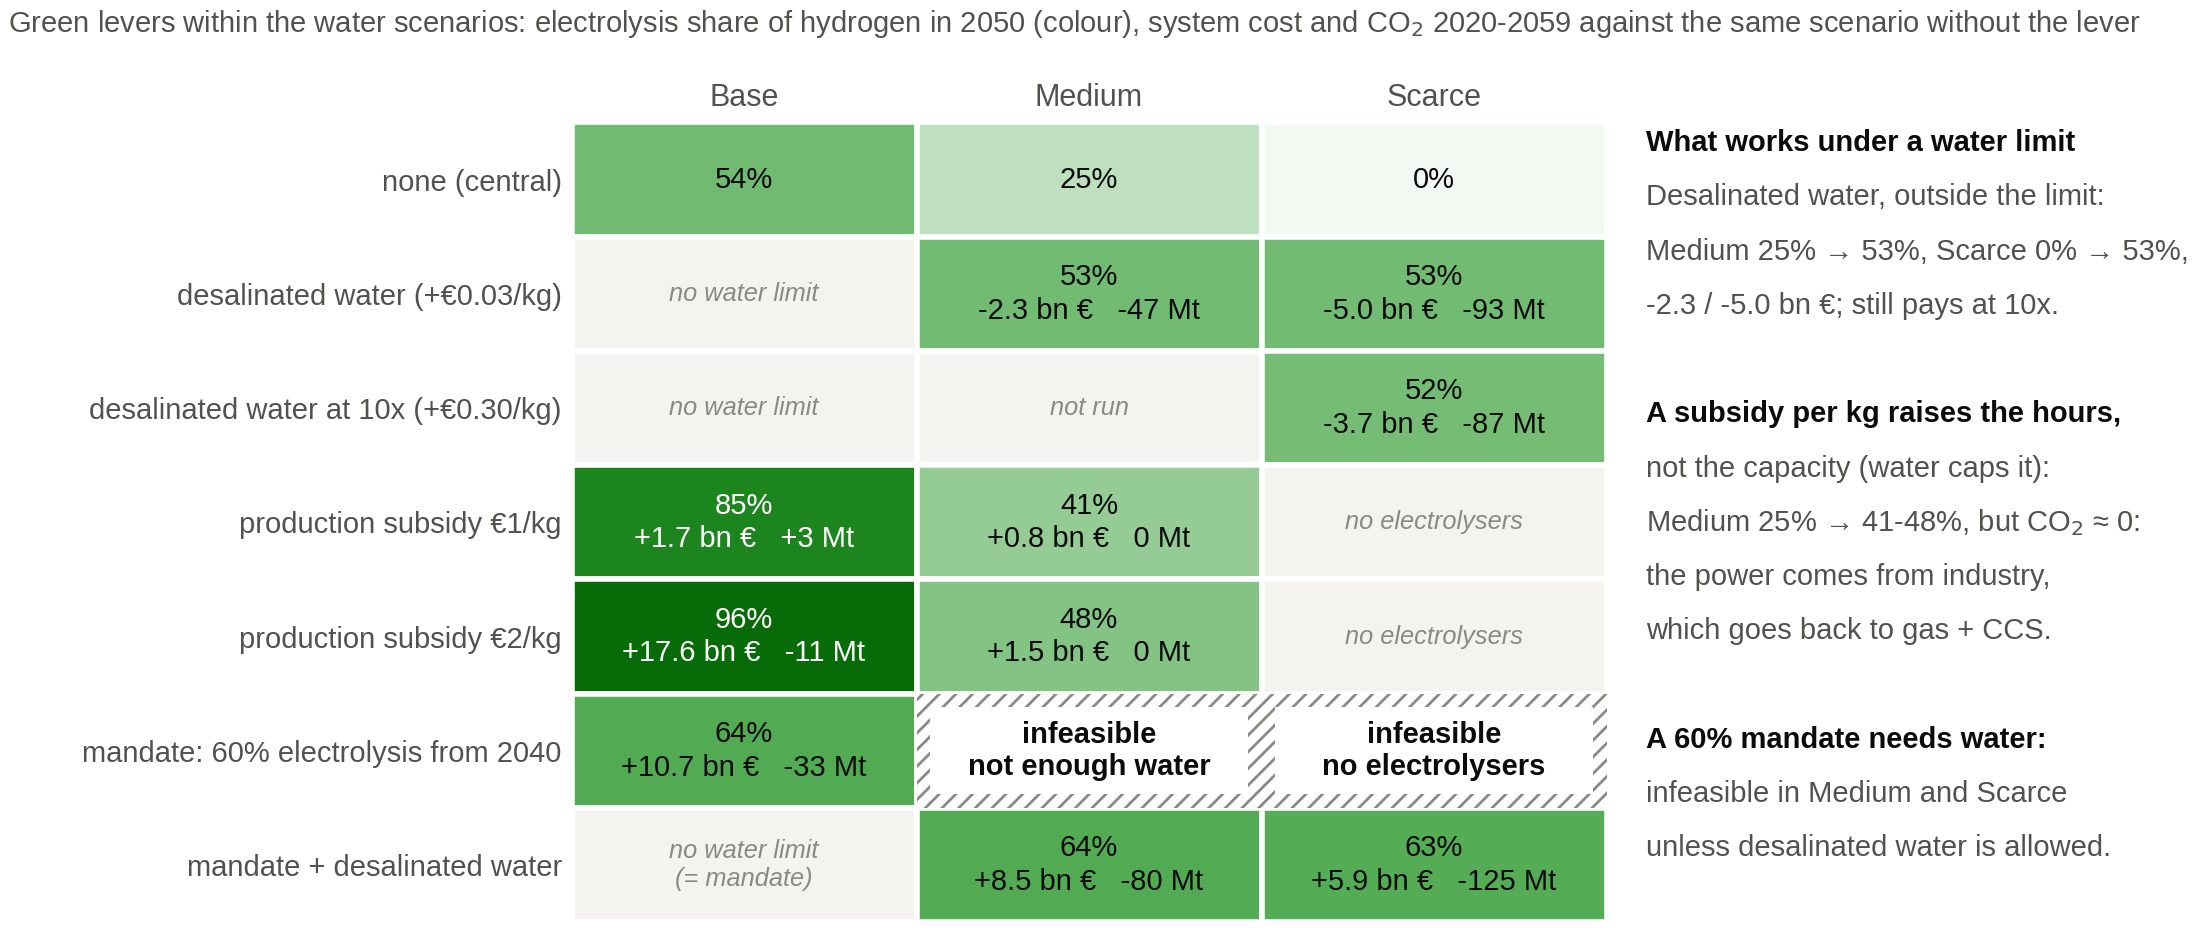

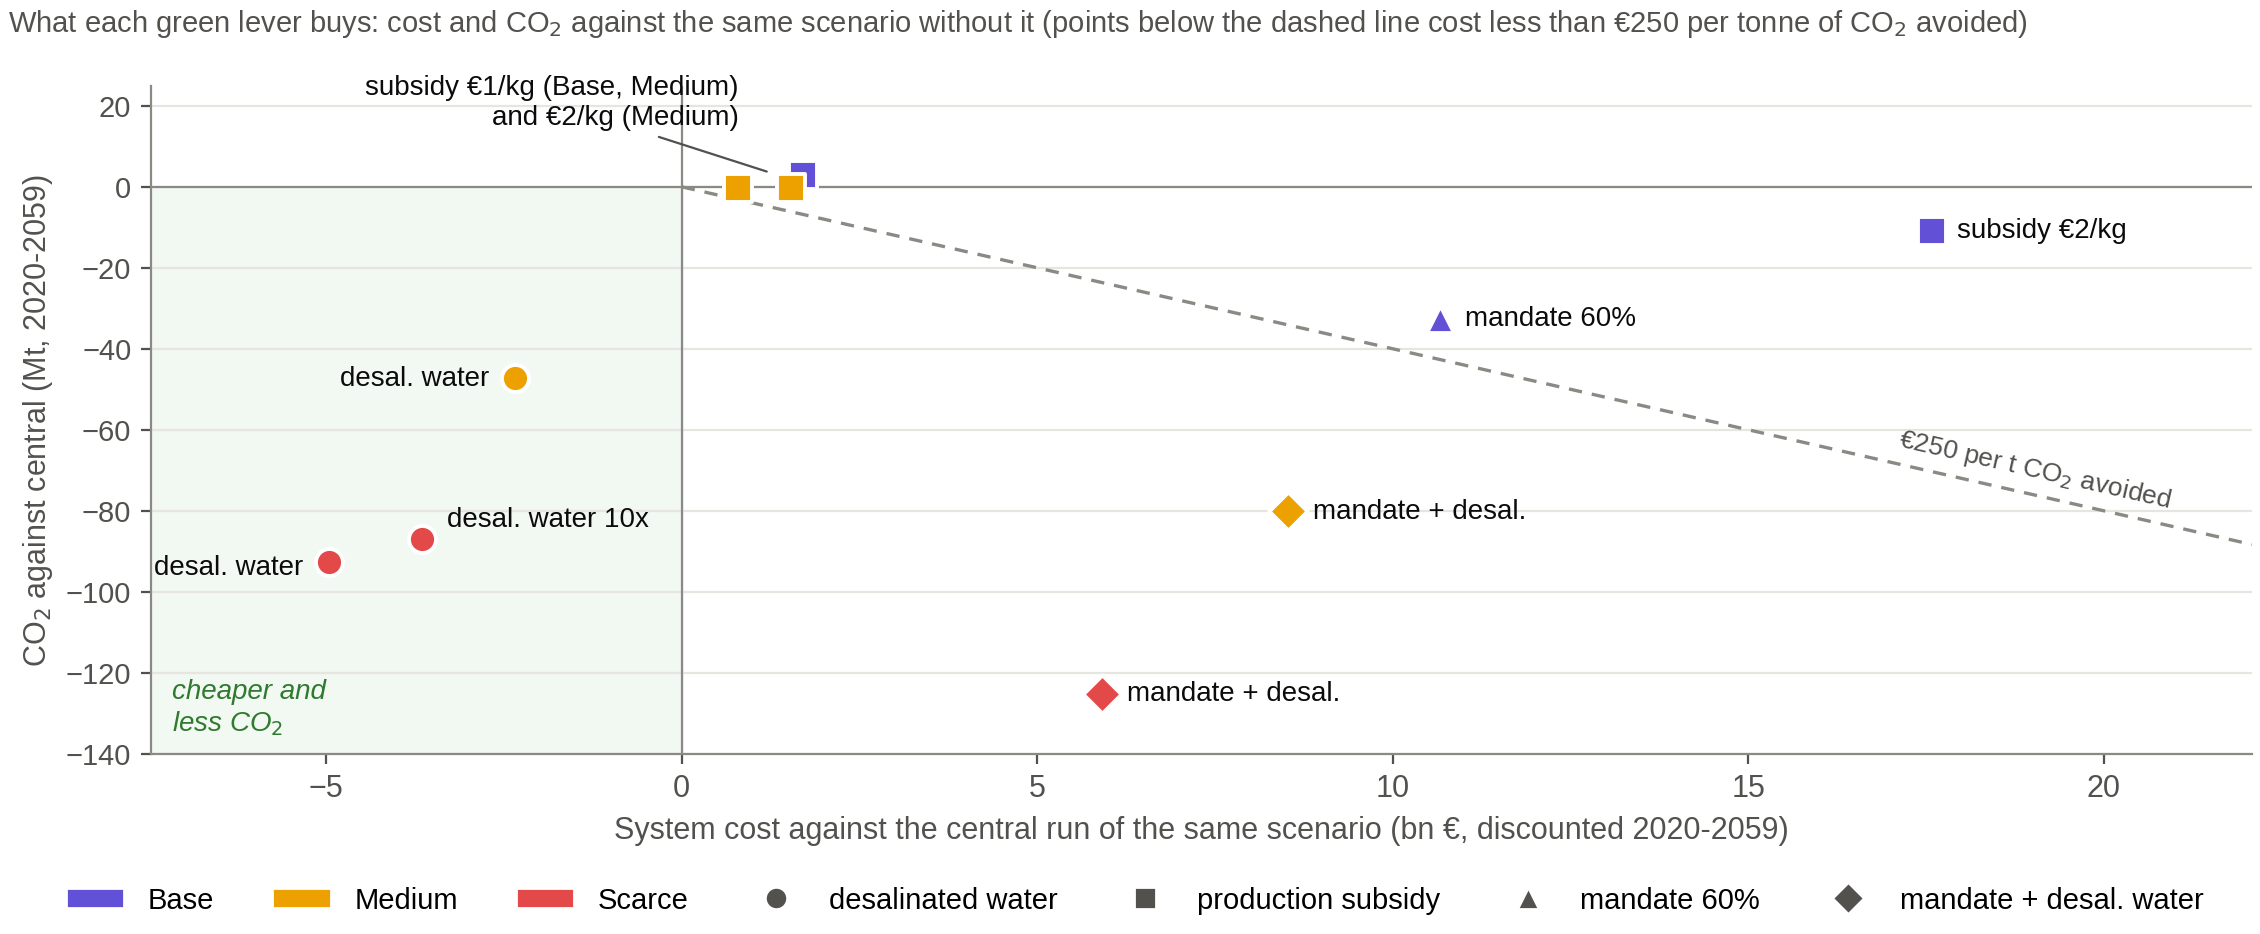

In [24]:
for stem in ['P16_green_levers', 'P16b_green_levers_cost_co2']:
    display(Image(f'results/plots/presentation/{stem}.png', width=900))

**Why a subsidy per kg hardly lowers CO₂ (check it here).** The subsidised electrolysers run more hours. The cell below shows where their electricity comes from: the change in what each link takes from its input bus in 2050 (Base with €1/kg minus Base).

In [25]:
def link_input_2050(n, y=2050):
    w = n.snapshot_weightings.generators.loc[y]
    p0 = n.links_t.p0.loc[y].mul(w, axis=0).sum() / 1e6                    # TWh per year
    return pd.DataFrame({'bus0': n.links.bus0, 'carrier': n.links.carrier, 'TWh': p0}).groupby(['bus0', 'carrier']).TWh.sum()

d = link_input_2050(load('S1_prod1')).sub(link_input_2050(runs['Base']), fill_value=0)
d[d.abs() > 0.3].round(1).to_frame('Base with €1/kg minus Base, 2050 (TWh/yr)')

S1_prod1: already on disk


Base with €1/kg minus Base, 2050 (TWh/yr)
bus0           carrier                                                                      
Biomass supply Biomass plant CCS                                                       -0.60
Electricity    Electrolyser                                                            19.20
               Industrial machinery - electricity                                     -15.10
Gas supply     Industrial HTP - fossil                                                  2.00
               Industrial HTP - fossil CCS                                             -2.30
               Industrial machinery - fossil                                           -5.20
               Industrial machinery - fossil CCS                                       23.10
               SMR CCS                                                                -19.50
Nuclear supply Nuclear plant                                                           -0.40

## 9. Figures for the presentation and the report

`figures/plots/presentation.py` draws every figure from the saved runs, in two styles, both in colour:
- **slides**: sized for the content box of the group's slide template (11.5 × 4.76 inches), in `results/plots/presentation`;
- **APA** (report): 6.5 inches wide, text 8 pt or more, no title or note in the image, in `results/plots/apa`, with the tables `Table_key_numbers` and `Table_green_levers`.

Presentation-ready document diagrams are in `figures_document/`: the model overview, Figures 1–3, and their source scripts. One PNG output is kept for each diagram.

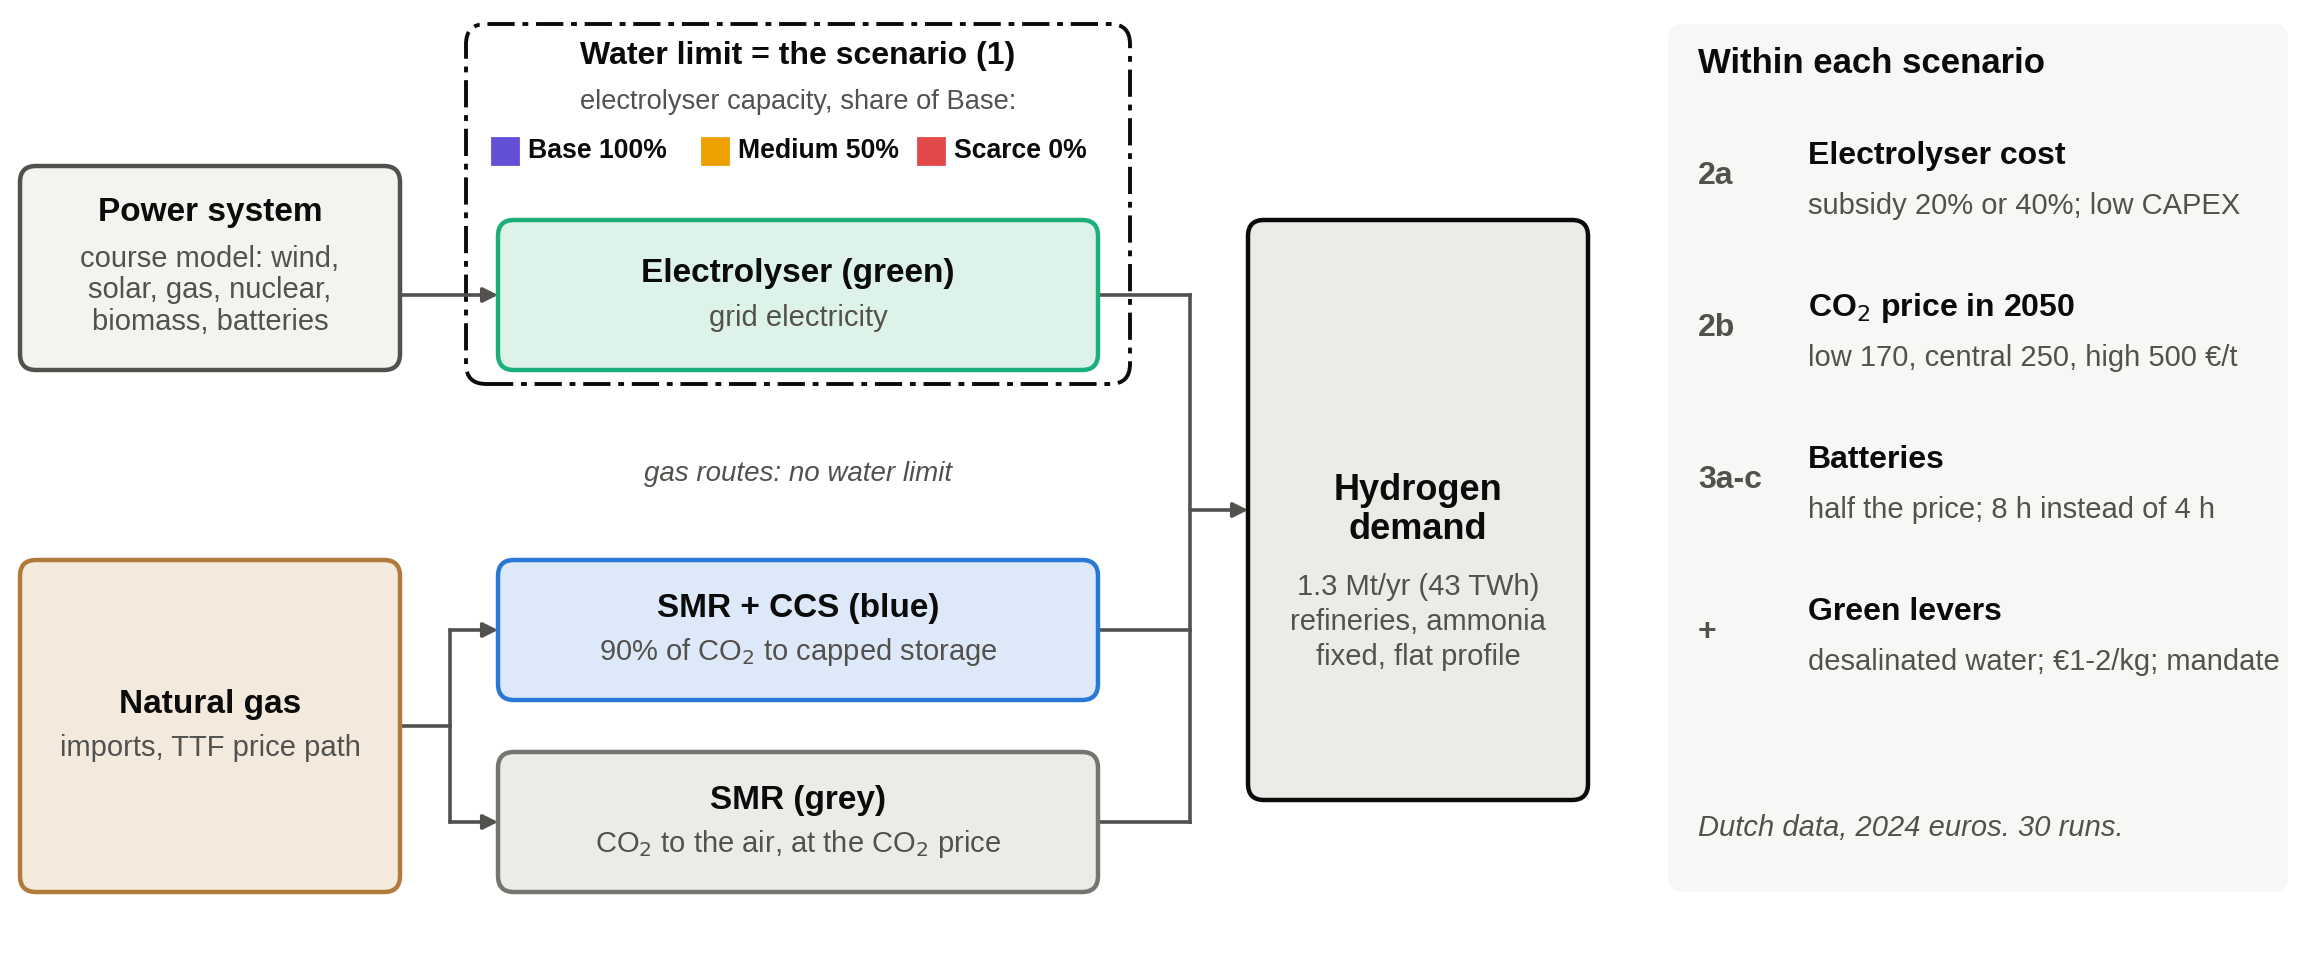

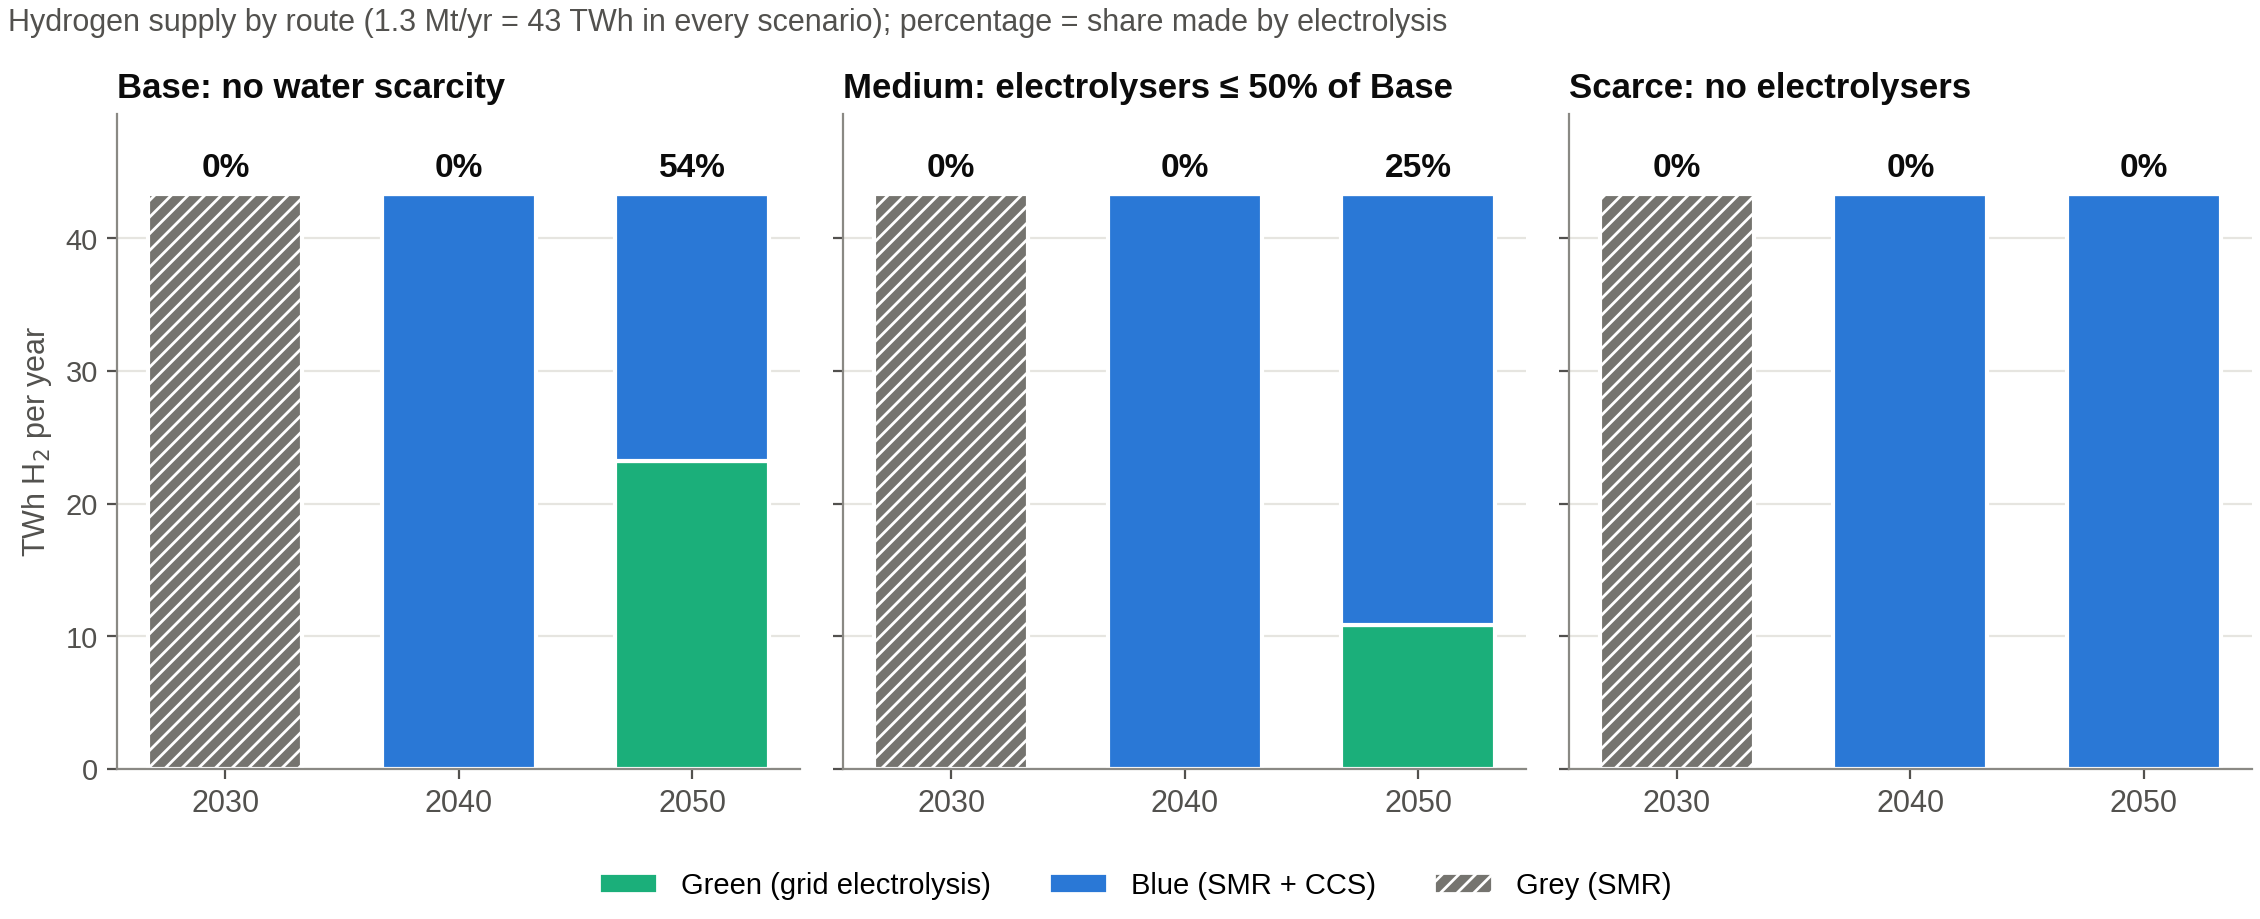

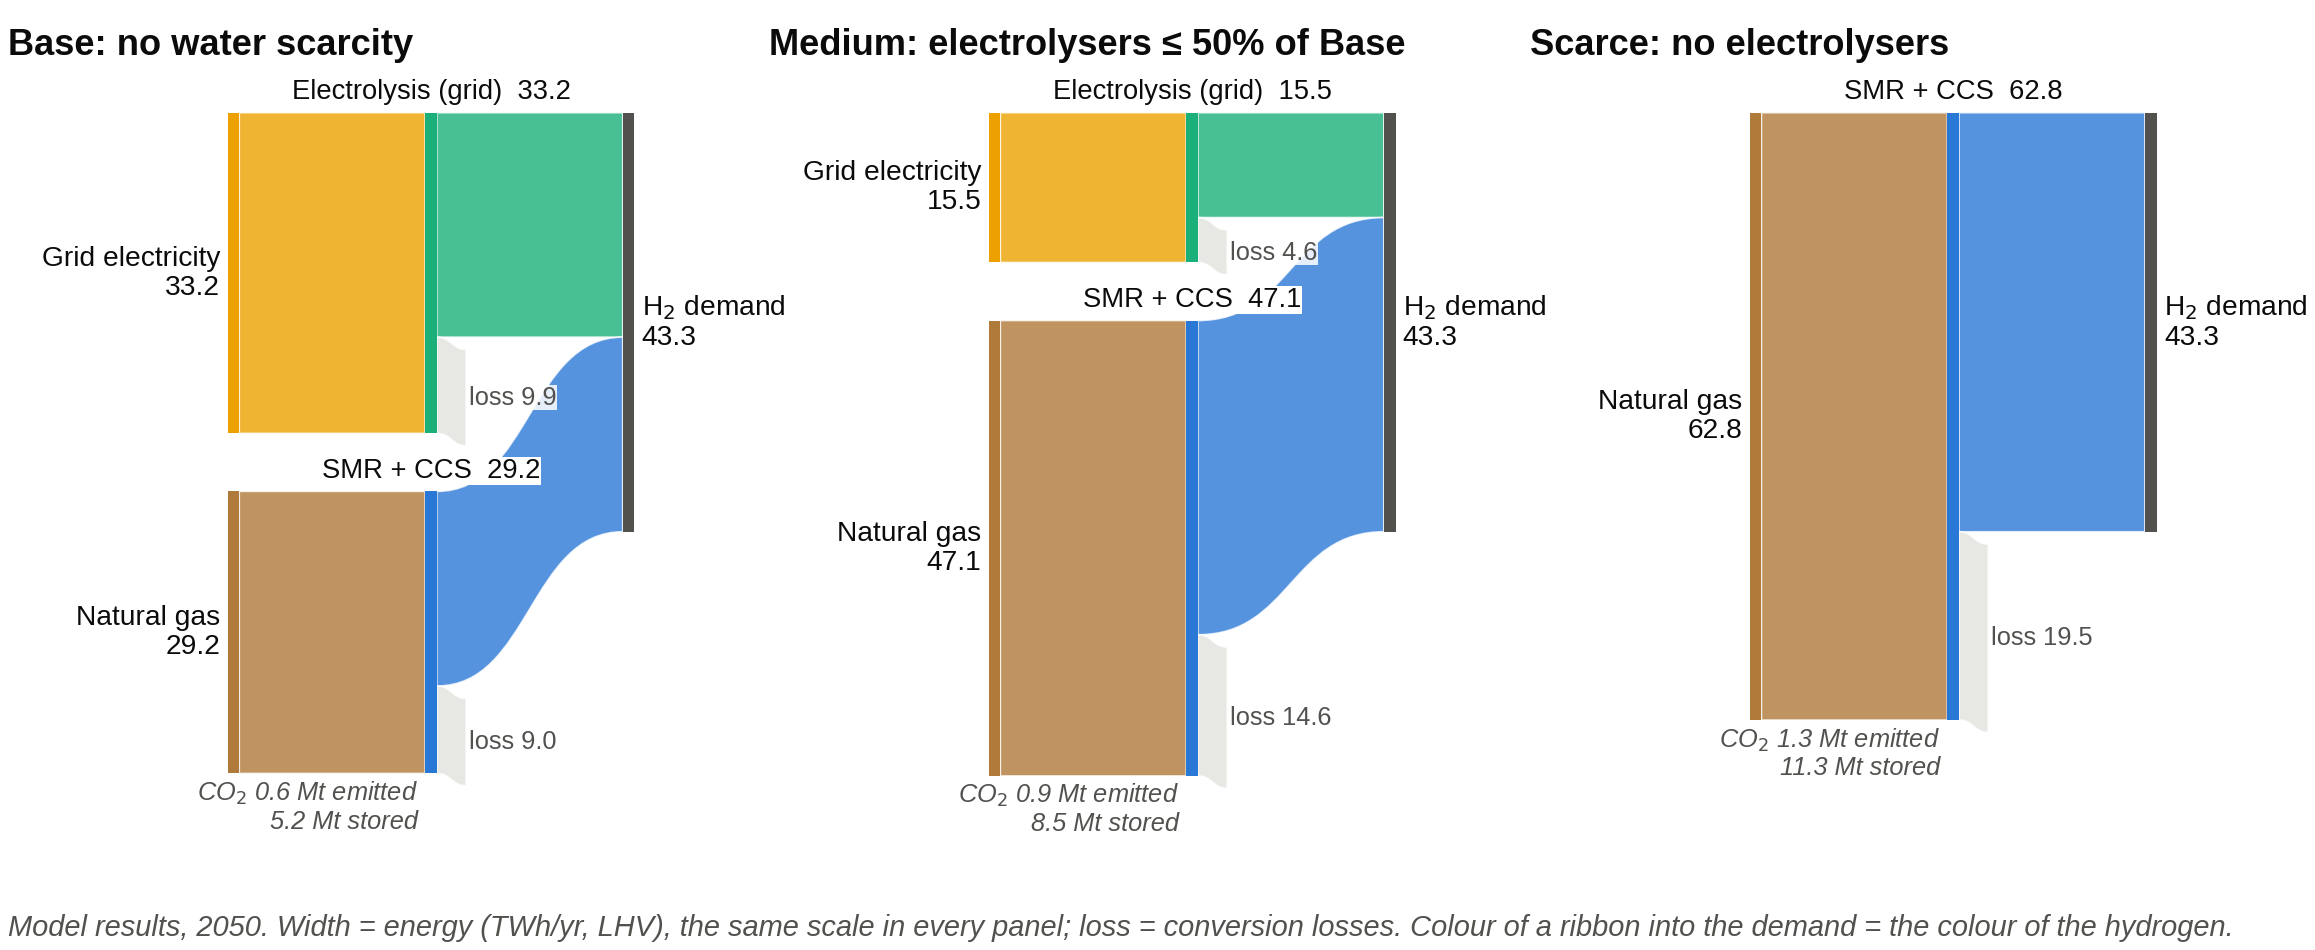

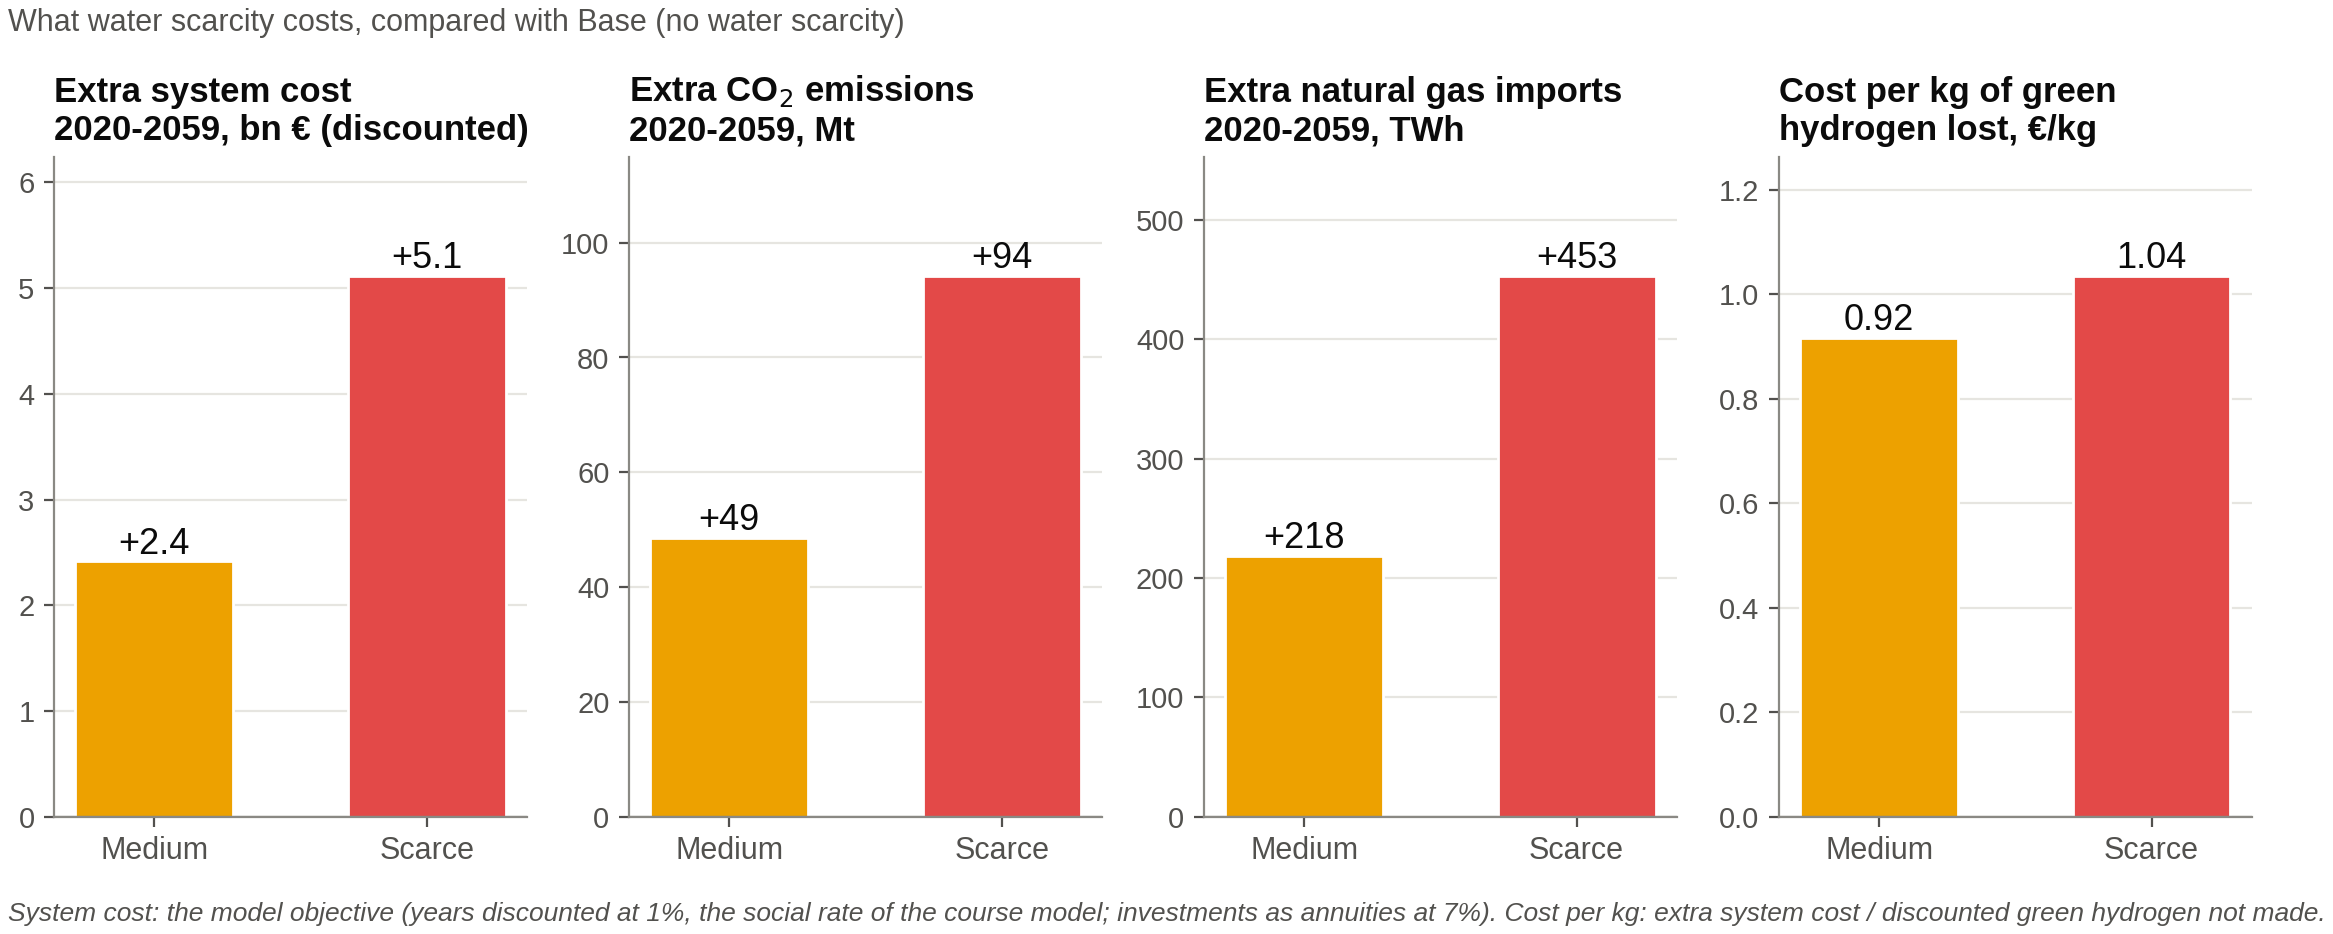

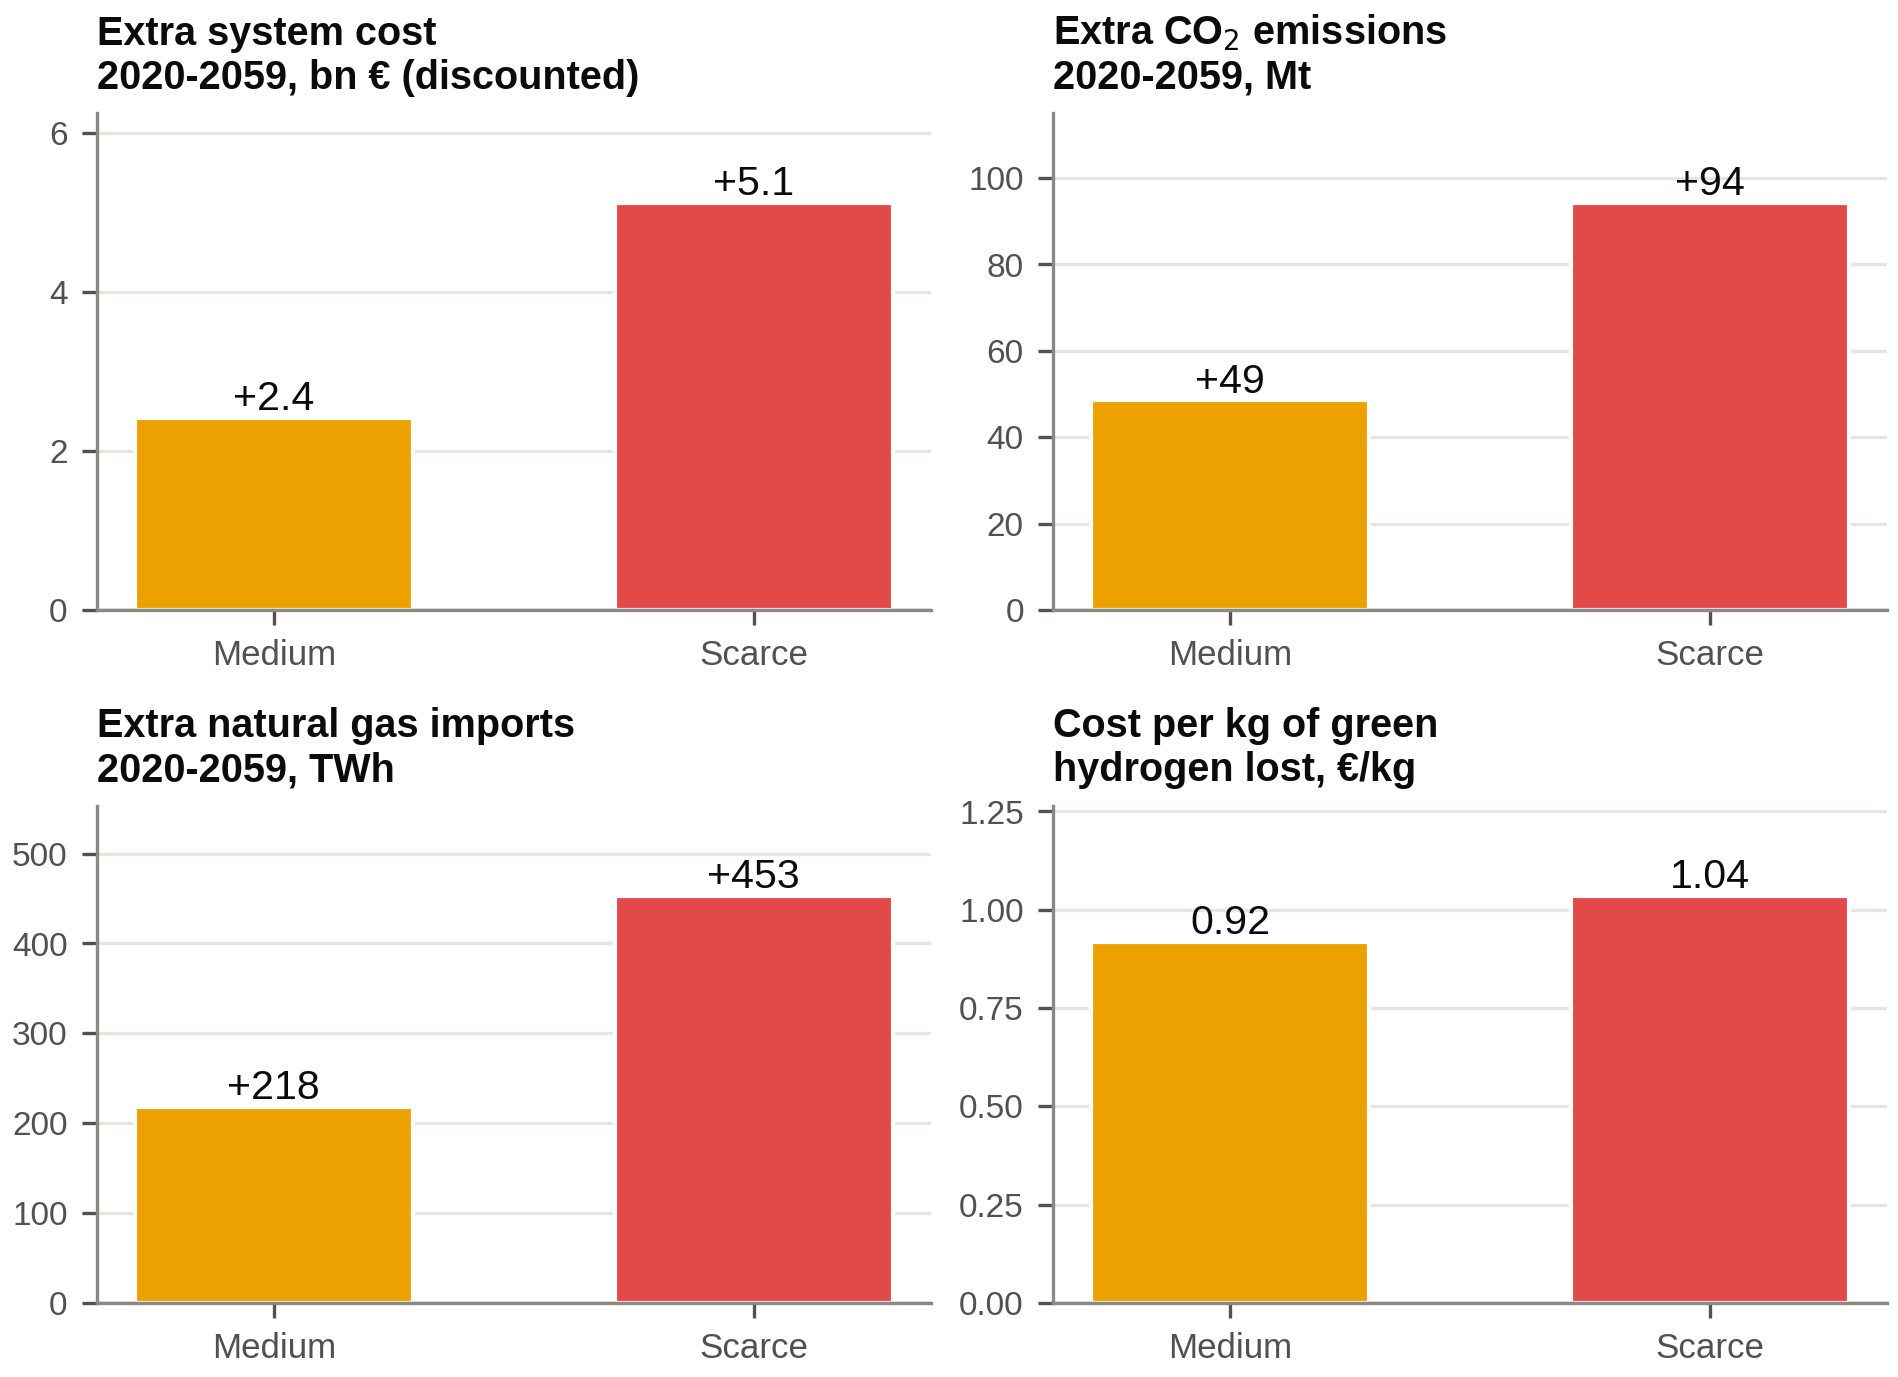

In [26]:
REDRAW = False                  # True = draw all figures again from the saved runs (both styles, about 20 minutes)
if REDRAW or not os.path.exists('results/plots/presentation/P01_h2_by_route.png'):
    pres.main(styles=('slide', 'apa'))
for stem in ['P01_h2_by_route', 'P02_h2_sankey_2050', 'P03_cost_of_water_scarcity']:
    display(Image(f'results/plots/presentation/{stem}.png', width=900))
display(Image('results/plots/apa/P03_cost_of_water_scarcity.png', width=600))      # the same figure in APA style

## 10. A decision for the group: what is the hydrogen used for?

Francesco set out two cases:
- If the hydrogen is **feedstock** (ammonia, refineries), it is a separate demand on top of the course demands.
- If it is **fuel for high-temperature heat**, the same amount of heat must come off the industrial HTP demand.

Our 1.3 Mt is today's feedstock demand, so the default is `'feedstock'`. `S1_htp_fuel` shows the other choice: the industrial HTP demand is reduced by the heat that this hydrogen would deliver in a furnace.

In [27]:
use = {'Feedstock (on top)': runs['Base'], 'Fuel for heat (HTP reduced)': load('S1_htp_fuel')}
print('HTP reduction (TWh/yr):', use['Fuel for heat (HTP reduced)'].meta.get('htp_reduction_twh'))
pd.concat({p: compare(use, period=p)[['Electrolysis share (%)', 'Gas use, total (TWh/yr)', 'CO2 total (Mt/yr)',
                                      'System cost (bn €/yr)']] for p in [2020, 2050]})

S1_htp_fuel: already on disk


HTP reduction (TWh/yr): {'2020': 25.997399999999992, '2030': 25.997399999999992, '2040': 25.997399999999992, '2050': 25.997399999999992}


Electrolysis share (%)  \
     run                                                   
2020 Feedstock (on top)                             0.00   
     Fuel for heat (HTP reduced)                    0.00   
2050 Feedstock (on top)                            53.56   
     Fuel for heat (HTP reduced)                   52.07   

                                  Gas use, total (TWh/yr)  CO2 total (Mt/yr)  \
     run                                                                       
2020 Feedstock (on top)                            374.39              85.18   
     Fuel for heat (HTP reduced)                   331.06              76.51   
2050 Feedstock (on top)                            147.24               4.66   
     Fuel for heat (HTP reduced)                   111.75              -2.44   

                                  System cost (bn €/yr)  
     run                                                 
2020 Feedstock (on top)                           18.37  
     Fuel for heat (HTP reduced)                  17.53  
2050 Feedstock (on top)                           31.46  
     Fuel for heat (HTP reduced)                  28.87

## 11. What is not in the model

- **Water.** There is no water resource; the scenarios limit electrolyser capacity instead. Water use is reported afterwards, in litres per kg: electrolysis 22, SMR 10, SMR + CCS 28.
- **The hydrogen network.** Left out to keep the model simple. Hydrogen storage is in the package with additions.
- **Hydrogen imports and an endogenous hydrogen demand** (hydrogen chosen by the model, e.g. for heat). These are not our question: the demand is given, and the scenarios differ only in water.

## 5. Reproducible batch run from the interface

The next cell uses the exact same `RUNS` registry and `run()` function as `run_batch.py`.


In [ ]:
# Run exactly the same scenario registry as run_batch.py.
# Set RUN_ALL_SCENARIOS=True and execute this cell to solve every configured run.
RUN_ALL_SCENARIOS = False
RERUN = False  # True forces a fresh solve; False reuses results/runs/*.nc


def run_all_scenarios(rerun=RERUN):
    results = {}
    for name in run_batch.RUNS:
        path = run_batch.run(name, solver=SOLVER, rerun=rerun)
        results[name] = path
    solved = [name for name, path in results.items() if path]
    missing = [name for name, path in results.items() if not path]
    print(f'Solved or loaded {len(solved)}/{len(results)} configured scenarios')
    if missing:
        print('Not saved (normally infeasible):', ', '.join(missing))
    return results


if RUN_ALL_SCENARIOS:
    RUN_RESULTS = run_all_scenarios()


In [ ]:
# Optional: regenerate figures from the saved runs in this package.
# This is intentionally separate from solving so the notebook can inspect or plot existing results.
RUN_ALL_FIGURES = False
if RUN_ALL_FIGURES:
    if 'pres' in globals():
        pres.main(styles=('slide', 'apa'))
    if 'sp' in globals():
        sp.main()
